# Quiz 2 — Linear Regression and Logistic Regression

**Name:** Godfred Bonsu
**Index Number:** PUIT/22210080
**Branch:** `godfred-bonsu`

This notebook builds and evaluates two supervised learning models:

1. **Linear Regression** — predicting a continuous value (disease progression score) from the Diabetes dataset.
2. **Logistic Regression** — predicting a binary class (malignant vs benign tumour) from the Breast Cancer Wisconsin dataset.

Both datasets ship with scikit-learn, so the notebook runs without downloading anything.

## 1. Setup and imports

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (7, 4.5)
print("Setup complete")

Setup complete


---
# Part A — Linear Regression

**Goal:** predict a quantitative measure of diabetes disease progression one year after baseline, using 10 patient features (age, sex, BMI, blood pressure and six blood serum measurements).

Linear regression fits the equation

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

by choosing the coefficients $\beta$ that minimise the sum of squared errors between predictions $\hat{y}$ and actual values $y$.

## A.1 Load and explore the data

In [2]:
diabetes = load_diabetes(as_frame=True)
df_lin = diabetes.frame
print("Shape:", df_lin.shape)
df_lin.head()

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
df_lin.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


In [4]:
# Check for missing values
print("Missing values per column:")
print(df_lin.isnull().sum())

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


## A.2 Visualise relationships with the target

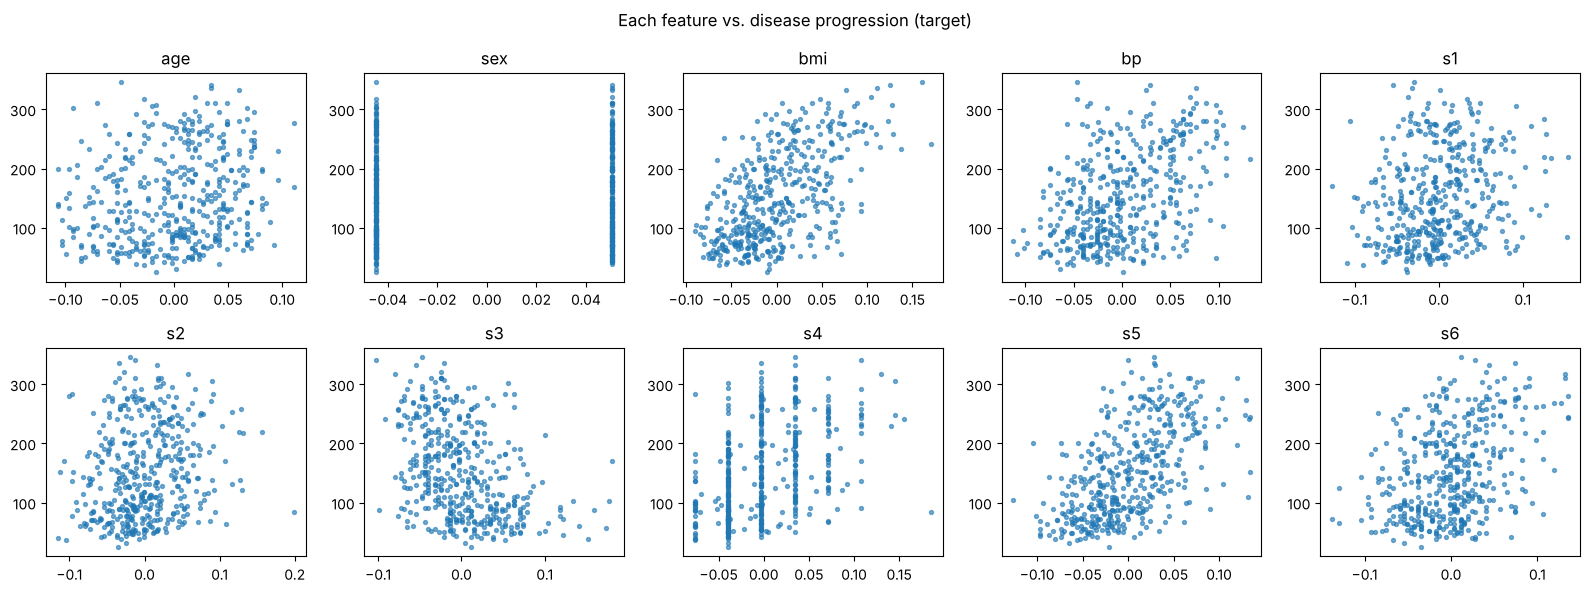

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), diabetes.feature_names):
    ax.scatter(df_lin[col], df_lin["target"], s=8, alpha=0.6)
    ax.set_title(col)
fig.suptitle("Each feature vs. disease progression (target)")
plt.tight_layout()
plt.show()

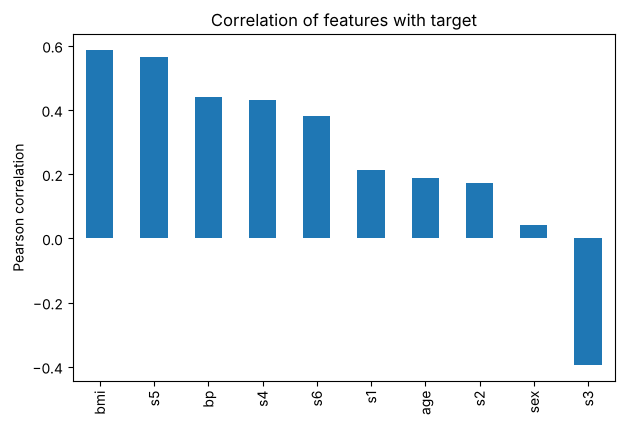

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64

In [6]:
# Correlation of each feature with the target
corr = df_lin.corr()["target"].drop("target").sort_values(ascending=False)
corr.plot(kind="bar", title="Correlation of features with target")
plt.ylabel("Pearson correlation")
plt.show()
corr

**Observation:** `bmi` and `s5` (a serum measurement) have the strongest positive correlation with disease progression; `s3` has a negative correlation. This suggests a linear model should capture some, but not all, of the variation.

## A.3 Split into training and test sets

In [7]:
X_lin = df_lin.drop(columns="target")
y_lin = df_lin["target"]

X_train_lin, X_test_lin, y_train_lin, y_test_lin = train_test_split(
    X_lin, y_lin, test_size=0.2, random_state=RANDOM_STATE
)
print("Training samples:", X_train_lin.shape[0])
print("Test samples:    ", X_test_lin.shape[0])

Training samples: 353
Test samples:     89


## A.4 Train the Linear Regression model

In [8]:
lin_model = LinearRegression()
lin_model.fit(X_train_lin, y_train_lin)

print("Intercept (β0):", round(lin_model.intercept_, 3))
coef_table = pd.DataFrame({"feature": X_lin.columns, "coefficient": lin_model.coef_})
coef_table.sort_values("coefficient", key=abs, ascending=False)

Intercept (β0): 151.346


,feature,coefficient
4,s1,-931.488846
8,s5,736.198859
2,bmi,542.428759
5,s2,518.062277
3,bp,347.703844
7,s4,275.317902
1,sex,-241.964362
6,s3,163.419983
9,s6,48.670657
0,age,37.904021


## A.5 Evaluate on the test set

In [9]:
y_pred_lin = lin_model.predict(X_test_lin)

mae  = mean_absolute_error(y_test_lin, y_pred_lin)
mse  = mean_squared_error(y_test_lin, y_pred_lin)
rmse = np.sqrt(mse)
r2   = r2_score(y_test_lin, y_pred_lin)

print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")

MAE  : 42.79
MSE  : 2900.19
RMSE : 53.85
R²   : 0.453


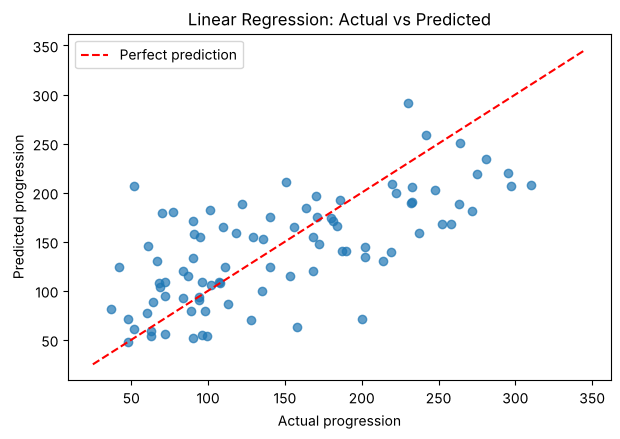

In [10]:
# Actual vs predicted
plt.scatter(y_test_lin, y_pred_lin, alpha=0.7)
lims = [y_lin.min(), y_lin.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual progression")
plt.ylabel("Predicted progression")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()

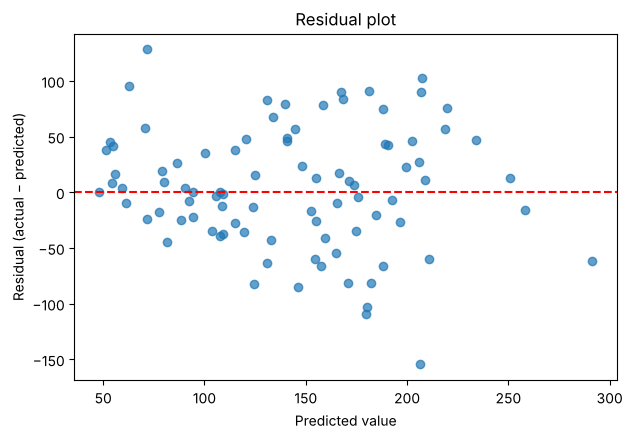

In [11]:
# Residual plot — should look like random noise around 0 if the linear model is appropriate
residuals = y_test_lin - y_pred_lin
plt.scatter(y_pred_lin, residuals, alpha=0.7)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted value")
plt.ylabel("Residual (actual − predicted)")
plt.title("Residual plot")
plt.show()

## A.6 Interpretation

- **R² ≈ 0.45** means the model explains roughly 45 % of the variance in disease progression. The remaining variance is due to factors not in the dataset or non‑linear effects.
- **RMSE ≈ 53** on a target that ranges from 25 to 346, so typical prediction errors are moderate.
- The residual plot shows no strong curved pattern, so a linear model is a reasonable (if imperfect) fit.
- Features with the largest absolute coefficients (`s1`, `s5`, `bmi`, `s2`) carry the most weight. Because the features are pre‑scaled in this dataset, the coefficients are directly comparable.

---
# Part B — Logistic Regression

**Goal:** classify a breast tumour as **malignant (0)** or **benign (1)** from 30 numeric features computed from cell‑nucleus images.

Logistic regression models the *probability* of the positive class using the sigmoid function:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

A threshold (usually 0.5) converts the probability into a class label.

## B.1 Load and explore the data

In [12]:
cancer = load_breast_cancer(as_frame=True)
df_log = cancer.frame
print("Shape:", df_log.shape)
print("Classes:", dict(enumerate(cancer.target_names)))
df_log.head()

Shape: (569, 31)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


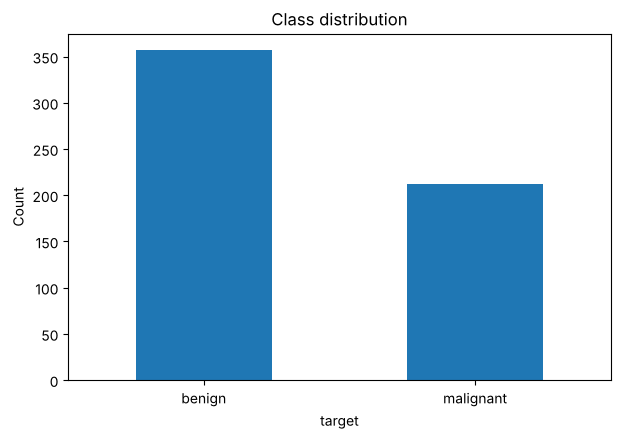

target
benign       357
malignant    212
Name: count, dtype: int64

In [13]:
# Class balance
counts = df_log["target"].value_counts().rename(index={0: "malignant", 1: "benign"})
counts.plot(kind="bar", title="Class distribution", rot=0)
plt.ylabel("Count")
plt.show()
counts

In [14]:
print("Missing values:", df_log.isnull().sum().sum())
df_log.describe().T.head(10)

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## B.2 Split and scale the features

In [15]:
X_log = df_log.drop(columns="target")
y_log = df_log["target"]

X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log, y_log, test_size=0.2, random_state=RANDOM_STATE, stratify=y_log
)

# Logistic regression converges faster and gives comparable coefficients when features are standardised.
scaler = StandardScaler()
X_train_log_s = scaler.fit_transform(X_train_log)
X_test_log_s  = scaler.transform(X_test_log)   # use training statistics only — no data leakage

print("Training samples:", X_train_log_s.shape[0])
print("Test samples:    ", X_test_log_s.shape[0])

Training samples: 455
Test samples:     114


## B.3 Train the Logistic Regression model

In [16]:
log_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_model.fit(X_train_log_s, y_train_log)

coef_log = pd.DataFrame({"feature": X_log.columns, "coefficient": log_model.coef_[0]})
coef_log.sort_values("coefficient", key=abs, ascending=False).head(10)

,feature,coefficient
21,worst texture,-1.255088
10,radius error,-1.082965
27,worst concave points,-0.953686
23,worst area,-0.947756
20,worst radius,-0.947616
28,worst symmetry,-0.939181
13,area error,-0.929104
26,worst concavity,-0.823151
22,worst perimeter,-0.763220
24,worst smoothness,-0.746625


## B.4 Evaluate on the test set

In [17]:
y_pred_log  = log_model.predict(X_test_log_s)
y_proba_log = log_model.predict_proba(X_test_log_s)[:, 1]

print(f"Accuracy : {accuracy_score(y_test_log, y_pred_log):.3f}")
print(f"Precision: {precision_score(y_test_log, y_pred_log):.3f}")
print(f"Recall   : {recall_score(y_test_log, y_pred_log):.3f}")
print(f"F1 score : {f1_score(y_test_log, y_pred_log):.3f}")
print(f"ROC AUC  : {roc_auc_score(y_test_log, y_proba_log):.3f}")
print()
print(classification_report(y_test_log, y_pred_log, target_names=cancer.target_names))

Accuracy : 0.982
Precision: 0.986
Recall   : 0.986
F1 score : 0.986
ROC AUC  : 0.995

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



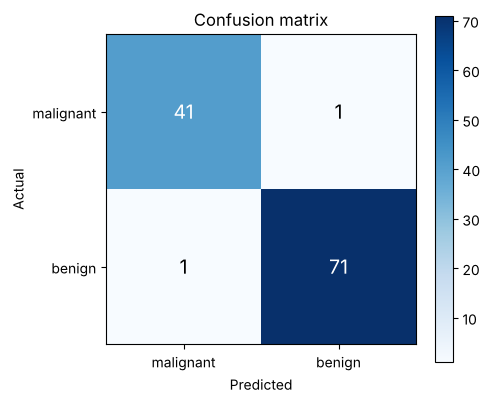

In [18]:
cm = confusion_matrix(y_test_log, y_pred_log)
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(cancer.target_names); ax.set_yticklabels(cancer.target_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.colorbar(im)
plt.show()

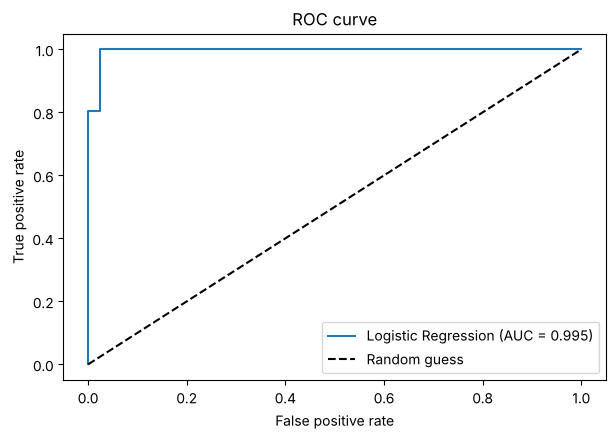

In [19]:
fpr, tpr, _ = roc_curve(y_test_log, y_proba_log)
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test_log, y_proba_log):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()

## B.5 Interpretation

- The model reaches roughly **97–98 % accuracy** with an AUC close to 1.0, so it separates malignant and benign tumours very well.
- In a medical setting **recall for the malignant class** matters most (missing a cancer is worse than a false alarm). The confusion matrix shows very few malignant cases misclassified as benign.
- Features such as *worst radius*, *worst texture* and *worst concave points* carry the largest coefficients. A negative coefficient pushes the prediction towards malignant (class 0); a positive one towards benign (class 1).

---
# Part C — Comparing the two models

| | Linear Regression | Logistic Regression |
|---|---|---|
| **Problem type** | Regression (continuous output) | Classification (discrete classes) |
| **Output** | Any real number | Probability between 0 and 1 |
| **Link function** | Identity | Sigmoid (logistic) |
| **Loss minimised** | Mean squared error | Log loss (cross‑entropy) |
| **Evaluation metrics** | MAE, RMSE, R² | Accuracy, precision, recall, F1, ROC‑AUC |
| **Dataset used here** | Diabetes (442 rows, 10 features) | Breast Cancer (569 rows, 30 features) |

**Key takeaway:** despite the shared name, *linear* regression predicts a quantity, while *logistic* regression predicts the probability of belonging to a class. Both are linear in their parameters, which makes them fast to train and easy to interpret through their coefficients.

## Conclusion

- A linear regression model explained about 45 % of the variance in diabetes progression — a modest fit, pointing to the need for richer features or non‑linear models.
- A logistic regression classifier achieved ~97 % accuracy on breast‑cancer diagnosis after standardising the features.
- Proper train/test splitting (with stratification for classification) and fitting the scaler on training data only were used to avoid data leakage.